# A17 mosaics: regularity vs. matched random simulations

Supplementary figure for the A17 populations, following Keeley, Eglen & Reese
(2020, J Comp Neurol, Fig. 7). `dA17 large` is far too sparse to test on its
own, so `A17 large` is tested both without and with it; `A17 small + large` pools the two main types. As in the paper,
each real mosaic is compared with 99 random simulations matched in cell number
and field, and constrained by soma size (no two somata may overlap; diameters
drawn from the real population's mean ± SD). Statistics:

- **NNRI**: nearest-neighbour regularity index, mean / SD of the NNDs. Cells
  closer to the field border than to their nearest neighbour are excluded.
- **VDRI**: Voronoi domain regularity index, mean / SD of the domain areas.
  Cells whose domain is not entirely inside the field are excluded.

Each statistic is reported as the regularity ratio (real / mean random) with
a one-sided Monte Carlo p-value from the real field's rank among the
simulations (so p >= 1 / (N_SIMULATIONS + 1)). A p-value close to 1 means the
real field is *less* regular than random (see `p_less` in the summary).

All populations are evaluated on the same small field in the densest part of
the volume. The simulations place cells uniformly within the field, so the
real mosaic must be homogeneous there too: on a large field the sparsely
sampled stripes (x ~ 200 and ~ 900 µm) make the real mosaic look clustered,
and every statistic came out less regular than random.

# Imports

In [1]:
import os
import sys

import matplotlib
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.collections import EllipseCollection, LineCollection
from matplotlib.patches import Rectangle

import cell_mosaics as cm

In [2]:
sys.path.append("../utils")

import data_io
from colors import colors
from plot import plot_scale_bar
from plot_cells import plot_cell_morphologies
from style import set_rc_params

In [3]:
set_rc_params()

# Data

In [4]:
config = data_io.get_data_config()
version = config.get("version", None)
file_path = data_io.get_file_path(config)

assert os.path.isfile(file_path), file_path

In [5]:
df = pd.read_parquet(file_path, columns=['celltype_final', 'soma_x_um', 'soma_y_um', 'soma_z_um', 'soma_rad_um',
                                       'hull_diameter', 'polar_dens_z'])
print(df.shape)

(63775, 7)


In [6]:
fig_dir = f'../figures/AC/v{version}'
os.makedirs(fig_dir, exist_ok=True)

# Parameters

In [7]:
# Each tested population and the cell types pooled into it.
POPULATIONS = {
    'A17 small': ['A17 small'],
    'A17 large': ['A17 large'],
    'A17 small + large': ['A17 small', 'A17 large'],
    'A17 large + dA17': ['A17 large', 'dA17 large'],
}
TYPE_COLORS = {
    'A17 small': "#1613BD",
    'A17 large': "#BB1BC9",
    'dA17 large': "#1A9B9F",
}
# Color of each tested population's real data (pooled populations get their own).
POPULATION_COLORS = {
    'A17 small': TYPE_COLORS['A17 small'],
    'A17 large': TYPE_COLORS['A17 large'],
    'A17 small + large': '#2F8FD0',
    'A17 large + dA17': TYPE_COLORS['A17 large'],
}
TYPES = ['A17 small', 'A17 large', 'dA17 large']
RANDOM_FILL = '#c4c3bf'
RANDOM_INK = '#5c5b57'

# Shared field (x_min, x_max, y_min, y_max) in µm: the densest 350 x 350 µm
# square, i.e. the one maximising the density of the sparser of A17 small and
# A17 large (25 µm grid search); cells outside it are ignored.
FIELD = (400, 750, 425, 775)

# Extent of all somata in the volume (any type), for the overview panels.
VOLUME = (df.soma_x_um.min(), df.soma_x_um.max(), df.soma_y_um.min(), df.soma_y_um.max())

N_SIMULATIONS = 99  # Keeley et al. (2020) convention
SEED = 42

# Type comparison (panel A)

In [8]:
df_types = df[df.celltype_final.isin(TYPES)]

# Example skeleton per type: of the cells with an SWC available, the one whose
# hull diameter is closest to the type median.
swc_ids = {os.path.splitext(f)[0] for f in os.listdir(config['skel_dir'])}
examples = {}
for celltype in TYPES:
    df_type = df_types[df_types.celltype_final == celltype]
    df_swc = df_type[df_type.index.astype(str).isin(swc_ids)]
    examples[celltype] = (df_swc.hull_diameter - df_type.hull_diameter.median()).abs().idxmin()
    print(f"{celltype:>10s}: example {examples[celltype]} (hull diameter "
          f"{df_swc.hull_diameter[examples[celltype]]:.0f} µm, type median {df_type.hull_diameter.median():.0f} µm, "
          f"{len(df_swc)} SWCs)")

# polar_dens_z: 80 bins of 0.5 µm from z = -20 µm.
Z_EDGES = (-20.0, 20.0)
z_um = Z_EDGES[0] + 0.5 * (np.arange(80) + 0.5)
z_profiles = {}
for celltype in TYPES:
    profiles = np.vstack(df_types.loc[df_types.celltype_final == celltype, 'polar_dens_z'])
    profiles = profiles / (profiles.max(axis=1, keepdims=True) + 1e-20)
    centroid = (profiles * z_um).sum(axis=1) / profiles.sum(axis=1)
    z_profiles[celltype] = profiles[np.argsort(centroid)]

 A17 small: example 720575940553345749 (hull diameter 152 µm, type median 158 µm, 1 SWCs)
 A17 large: example 720575940563586331 (hull diameter 647 µm, type median 628 µm, 1 SWCs)
dA17 large: example 720575940556720234 (hull diameter 645 µm, type median 671 µm, 3 SWCs)


# Real mosaics

In [9]:
def in_bounds(positions, bounds):
    return ((positions[:, 0] >= bounds[0]) & (positions[:, 0] <= bounds[1])
            & (positions[:, 1] >= bounds[2]) & (positions[:, 1] <= bounds[3]))


mosaics = {}
for population, celltypes in POPULATIONS.items():
    df_pop = df[df.celltype_final.isin(celltypes)]
    all_positions = df_pop[['soma_x_um', 'soma_y_um']].to_numpy()
    all_diameters = 2 * df_pop.soma_rad_um.to_numpy()
    in_field = in_bounds(all_positions, FIELD)
    mosaics[population] = {
        'all_positions': all_positions,
        'all_diameters': all_diameters,
        'all_colors': [TYPE_COLORS[ct] for ct in df_pop.celltype_final],
        'positions': all_positions[in_field],
        'diameters': all_diameters[in_field],
        'soma_diameter_mean': float(np.nanmean(all_diameters[in_field])),
        'soma_diameter_sd': float(np.nanstd(all_diameters[in_field])),
    }
    n_per_type = ', '.join(f"{ct} {np.sum(df_pop.celltype_final.to_numpy()[in_field] == ct)}"
                           for ct in celltypes)
    print(f"{population:>16s}: {len(df_pop):3d} cells, {in_field.sum():3d} in field ({n_per_type}), "
          f"soma diameter {mosaics[population]['soma_diameter_mean']:.1f} "
          f"± {mosaics[population]['soma_diameter_sd']:.1f} µm")

       A17 small: 302 cells, 127 in field (A17 small 127), soma diameter 10.6 ± 1.0 µm
       A17 large: 394 cells, 139 in field (A17 large 139), soma diameter 11.8 ± 0.7 µm
A17 small + large: 696 cells, 266 in field (A17 small 127, A17 large 139), soma diameter 11.2 ± 1.1 µm
A17 large + dA17: 438 cells, 144 in field (A17 large 139, dA17 large 5), soma diameter 11.8 ± 0.7 µm


# Matched random simulations

In [10]:
def spacing(n_cells, field=FIELD):
    """Mean intercell spacing, 1 / sqrt(density), in µm."""
    return np.sqrt((field[1] - field[0]) * (field[3] - field[2]) / n_cells)


def nnd_and_areas(positions, field=FIELD):
    """NNDs and Voronoi domain areas after the Keeley et al. (2020) border rules."""
    nnd = cm.nearest_neighbor_distances(positions)[cm.nnd_border_mask(positions, field)]
    areas = cm.voronoi_analysis(positions, interior_mask=cm.voronoi_border_mask(positions, field))['areas']
    return nnd, areas


results = {}
for i, population in enumerate(POPULATIONS):
    mosaic = mosaics[population]
    # The effective radius isn't plotted, but compare_to_random_simulations
    # always computes it; fix its radius per type so it is comparable across fields.
    drp_kwargs = {'n_bins': 20, 'max_radius': 2.5 * spacing(len(mosaic['positions']))}
    res = cm.compare_to_random_simulations(
        mosaic['positions'], FIELD,
        soma_diameter_mean=mosaic['soma_diameter_mean'],
        soma_diameter_sd=mosaic['soma_diameter_sd'],
        n_simulations=N_SIMULATIONS, drp_kwargs=drp_kwargs,
        seed=SEED + i, return_simulations=True,
    )
    res['real_nnd'], res['real_areas'] = nnd_and_areas(mosaic['positions'])
    sim_dists = [nnd_and_areas(sim_positions) for sim_positions, _ in res['simulations']]
    res['sim_nnd'] = [nnd for nnd, _ in sim_dists]
    res['sim_areas'] = [areas for _, areas in sim_dists]
    results[population] = res

In [11]:
summary = pd.DataFrame([
    {
        'population': population,
        'n_cells': res['observed']['n_cells'],
        'n_nnd_interior': res['observed']['n_nnd_interior'],
        'n_voronoi_interior': res['observed']['n_voronoi_interior'],
        'density_per_mm2': res['observed']['density'] * 1e6,
        **{f'{label}_{key}': res[stat][key]
           for label, stat in [('NNRI', 'nnd_regularity_index'), ('VDRI', 'voronoi_regularity_index')]
           for key in ['observed', 'simulated_mean', 'simulated_sd', 'ratio', 'p_greater', 'p_less']},
    }
    for population, res in results.items()
]).set_index('population')
summary.T.round(3)

population,A17 small,A17 large,A17 small + large,A17 large + dA17
n_cells,127.000,139.000,266.000,144.000
n_nnd_interior,102.000,115.000,232.000,118.000
n_voronoi_interior,91.000,100.000,211.000,103.000
density_per_mm2,1036.735,1134.694,2171.429,1175.510
NNRI_observed,3.379,2.552,2.563,2.563
NNRI_simulated_mean,3.189,3.690,5.033,3.790
NNRI_simulated_sd,0.248,0.274,0.300,0.309
NNRI_ratio,1.060,0.692,0.509,0.676
NNRI_p_greater,0.180,1.000,1.000,1.000
NNRI_p_less,0.830,0.010,0.010,0.010


# Figure

In [12]:
def draw_field(ax, positions, diameters, color, bounds=FIELD, cell_colors=None, title=None):
    """Somata at their real size, with Voronoi domains of the cells the VDRI keeps.

    Shows `bounds`; if that is larger than FIELD, the field is outlined dashed.
    """
    in_field = in_bounds(positions, FIELD)
    keep_in_field = cm.voronoi_border_mask(positions[in_field], FIELD)
    polygons, _, index = cm.voronoi_domain_polygons(positions[in_field])
    segments = [np.vstack([p, p[:1]]) for p, j in zip(polygons, index) if keep_in_field[j]]
    ax.add_collection(LineCollection(segments, colors=color, linewidths=0.4, alpha=0.7))

    # Cells excluded from the VDRI (outside the field, or domain not entirely
    # inside it) are faded.
    keep = np.zeros(len(positions), dtype=bool)
    keep[in_field] = keep_in_field
    cell_colors = cell_colors if cell_colors is not None else [color] * len(positions)
    facecolors = [matplotlib.colors.to_rgba(c, 1.0 if k else 0.35) for c, k in zip(cell_colors, keep)]
    ax.add_collection(EllipseCollection(
        diameters, diameters, np.zeros(len(diameters)), units='xy', offsets=positions,
        offset_transform=ax.transData, facecolors=facecolors, edgecolors='none'))

    if bounds != FIELD:
        ax.add_patch(Rectangle((FIELD[0], FIELD[2]), FIELD[1] - FIELD[0], FIELD[3] - FIELD[2],
                               fill=False, edgecolor=RANDOM_INK, linestyle='--', linewidth=0.7))

    ax.set(xlim=bounds[:2], ylim=bounds[2:], xticks=[], yticks=[])
    ax.set_aspect('equal')
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(RANDOM_FILL)
        spine.set_linewidth(0.6)
    if title:
        ax.set_title(title, fontsize=8, pad=3)


def format_p(p):
    return f"p = {p:.2f}" if p >= 0.01 else f"p = {p:.3f}"


def draw_index_bars(ax, stat_res, color, ylabel):
    """Real index (single field) vs. the random simulations (mean ± SD, one dot each)."""
    sims = stat_res['simulated'][~np.isnan(stat_res['simulated'])]
    ax.bar(0, stat_res['observed'], width=0.6, color=color)
    ax.bar(1, sims.mean(), width=0.6, color=RANDOM_FILL, yerr=sims.std(), capsize=2,
           error_kw={'elinewidth': 0.7, 'capthick': 0.7, 'ecolor': RANDOM_INK})
    rng = np.random.default_rng(0)
    ax.scatter(1 + rng.uniform(-0.17, 0.17, len(sims)), sims, s=2, color=RANDOM_INK,
               linewidths=0, alpha=0.6, zorder=3)
    ax.set_xticks([0, 1], ['real', 'random'], rotation=90)
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylabel(ylabel, labelpad=1)
    ax.set_title(f"ratio {stat_res['ratio']:.2f}\n{format_p(stat_res['p_greater'])}", fontsize=7, pad=2)


def frequency(samples, bins):
    """Percentage frequency distribution of `samples` over `bins`."""
    return np.histogram(samples, bins)[0] / max(len(samples), 1) * 100


def draw_distribution(ax, real, sims, bins, color, xlabel, scale=1.0):
    """Real frequency distribution vs. random simulations (mean ± SD over simulations)."""
    centers = 0.5 * (bins[:-1] + bins[1:]) / scale
    sim_freq = np.array([frequency(s, bins) for s in sims])
    mean, sd = sim_freq.mean(axis=0), sim_freq.std(axis=0)
    ax.fill_between(centers, mean - sd, mean + sd, color=RANDOM_FILL, alpha=0.7, linewidth=0)
    ax.plot(centers, mean, color=RANDOM_INK, lw=1, label='random')
    ax.plot(centers, frequency(real, bins), color=color, lw=1.2, label='real')
    ax.set_xlim(bins[0] / scale, bins[-1] / scale)
    ax.set_ylim(bottom=0)
    ax.set_xlabel(xlabel)


def distribution_bins(res, real_key, sim_key, n_bins=16, quantile=0.99):
    """Shared bins for one type's real and simulated values, cut at a high quantile."""
    values = np.concatenate([res[real_key], *res[sim_key]])
    return np.linspace(0, np.quantile(values, quantile), n_bins + 1)

[Info] scikit-sparse not found. Falling back to scipy.sparse.linalg.spsolve.


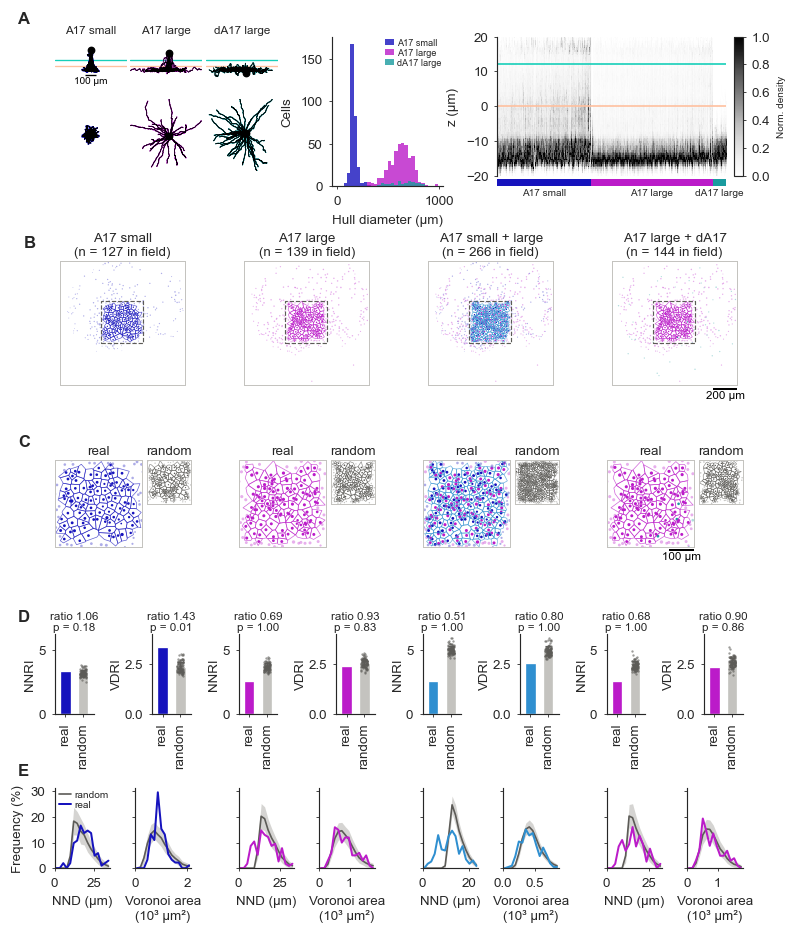

In [13]:
n_pop = len(POPULATIONS)
fig = plt.figure(figsize=(7.4, 9.0))
outer = fig.add_gridspec(5, n_pop, height_ratios=(1.5, 1.25, 1.0, 0.8, 0.8), hspace=0.7, wspace=0.35)

# Row A: example skeletons | hull diameter histogram | z-profile heatmaps.
grid_a = outer[0, :].subgridspec(1, 3, width_ratios=(3, 1.5, 3.3), wspace=0.28)
axs_skel = grid_a[0].subgridspec(2, 3, height_ratios=(1.7, 4), wspace=0.05, hspace=0.05).subplots()
ax_hull = fig.add_subplot(grid_a[1])
grid_z = grid_a[2].subgridspec(2, 2, width_ratios=(1, 0.04), height_ratios=(1, 0.05), wspace=0.06, hspace=0.04)
ax_zprof = fig.add_subplot(grid_z[0, 0])
ax_ztype = fig.add_subplot(grid_z[1, 0], sharex=ax_zprof)
ax_zcbar = fig.add_subplot(grid_z[0, 1])

type_colors = [TYPE_COLORS[t] for t in TYPES]
rad_skel = 330
plot_cell_morphologies(
    df_types.loc[[examples[t] for t in TYPES]], rad=rad_skel, skel_dir=config['skel_dir'],
    color_list=type_colors, size=100, show_on_tsne=False, fig=fig, axs=axs_skel,
    sb_fontsize=6, zlim=(-30, 60))
for ax, celltype in zip(axs_skel[0], TYPES):
    ax.set_title(celltype, fontsize=7, pad=2)
# Axis labels only on the outer panels; xz panels share the xy panels' x axis.
for col in range(3):
    axs_skel[0, col].set(xlabel='')
    axs_skel[0, col].tick_params(labelbottom=False)
    for row in range(2):
        if col:
            axs_skel[row, col].set(ylabel='')
            axs_skel[row, col].tick_params(labelleft=False)

for ax in axs_skel.flat:
    ax.set(xlabel='', ylabel='', xticks=[], yticks=[])
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)


bins = np.linspace(0, df_types.hull_diameter.max() * 1.02, 31)
for celltype in TYPES:
    ax_hull.hist(df_types.loc[df_types.celltype_final == celltype, 'hull_diameter'], bins=bins,
                 color=TYPE_COLORS[celltype], alpha=0.8, linewidth=0, label=celltype)
ax_hull.set(xlabel='Hull diameter (µm)', ylabel='Cells')
ax_hull.spines[['left', 'bottom']].set_visible(True)
ax_hull.spines[['top', 'right']].set_visible(False)
ax_hull.legend(fontsize=5.5, frameon=False, loc='upper right', handlelength=1)

# All cells in one heatmap (types in order), with a bar below marking each type.
z_all = np.hstack([z_profiles[t].T for t in TYPES])
im = ax_zprof.imshow(z_all, aspect='auto', interpolation='none', origin='lower',
                     extent=(0, z_all.shape[1], *Z_EDGES), rasterized=True, cmap='Grays')
ax_zprof.axhline(0, ls='-', c=colors['salmon'], lw=1)
ax_zprof.axhline(12, ls='-', c=colors['cyan'], lw=1)
ax_zprof.set(xticks=[], ylabel='z (µm)')
ax_zprof.spines['left'].set_visible(True)
ax_zprof.spines[['top', 'right', 'bottom']].set_visible(False)

edges = np.cumsum([0] + [len(z_profiles[t]) for t in TYPES])
for celltype, x0, x1 in zip(TYPES, edges[:-1], edges[1:]):
    ax_ztype.axvspan(x0, x1, color=TYPE_COLORS[celltype], linewidth=0)
    ax_ztype.text((x0 + x1) / 2, -0.4, celltype, ha='center', va='top', fontsize=6,
                  transform=ax_ztype.get_xaxis_transform())
ax_ztype.set_xlim(0, z_all.shape[1])
ax_ztype.axis('off')
cbar = fig.colorbar(im, cax=ax_zcbar)
cbar.set_label('Norm. density', fontsize=6)

axs_real = [fig.add_subplot(outer[1, col]) for col in range(n_pop)]
# Row B: zoom on the real field (2/3 of the width) next to one random simulation (1/3).
axs_zoom = []
axs_random = []
for col in range(n_pop):
    ax_zoom, ax_random = outer[2, col].subgridspec(1, 2, width_ratios=(2, 1), wspace=0.08).subplots()
    for ax in (ax_zoom, ax_random):
        ax.set_anchor('N')  # top-align both square panels
    axs_zoom.append(ax_zoom)
    axs_random.append(ax_random)
axs_bars = [outer[3, col].subgridspec(1, 2, wspace=1.5).subplots() for col in range(n_pop)]
axs_dist = [outer[4, col].subgridspec(1, 2, wspace=0.45).subplots() for col in range(n_pop)]

for col, (population, celltypes) in enumerate(POPULATIONS.items()):
    color = POPULATION_COLORS[population]
    mosaic = mosaics[population]
    res = results[population]

    draw_field(axs_real[col], mosaic['all_positions'], mosaic['all_diameters'], color,
               bounds=VOLUME, cell_colors=mosaic['all_colors'],
               title=f"{population}\n(n = {len(mosaic['positions'])} in field)")
    draw_field(axs_zoom[col], mosaic['all_positions'], mosaic['all_diameters'], color,
               cell_colors=mosaic['all_colors'], title='real')
    sim_positions, sim_diameters = res['simulations'][0]
    draw_field(axs_random[col], sim_positions, sim_diameters, RANDOM_INK, title='random')

    ax_nnri, ax_vdri = axs_bars[col]
    draw_index_bars(ax_nnri, res['nnd_regularity_index'], color, 'NNRI')
    draw_index_bars(ax_vdri, res['voronoi_regularity_index'], color, 'VDRI')

    ax_nnd, ax_area = axs_dist[col]
    draw_distribution(ax_nnd, res['real_nnd'], res['sim_nnd'],
                      distribution_bins(res, 'real_nnd', 'sim_nnd'), color, 'NND (µm)')
    draw_distribution(ax_area, res['real_areas'], res['sim_areas'],
                      distribution_bins(res, 'real_areas', 'sim_areas'), color,
                      'Voronoi area\n(10³ µm²)', scale=1e3)
    ax_nnd.set_ylabel('Frequency (%)')

# Share each index's y axis across types so the three columns are comparable.
for k in range(2):
    y_max = max(axs_bars[col][k].get_ylim()[1] for col in range(n_pop))
    for col in range(n_pop):
        axs_bars[col][k].set_ylim(0, y_max)

# Share the frequency axis (label, limits, ticks) across all distribution panels.
y_max = max(ax.get_ylim()[1] for pair in axs_dist for ax in pair)
for col, pair in enumerate(axs_dist):
    for k, ax in enumerate(pair):
        ax.set_ylim(0, y_max)
        ax.set_yticks(np.arange(0, y_max, 10))
        if col or k:
            ax.set_ylabel('')
            ax.tick_params(labelleft=False)

axs_dist[0][0].legend(loc='upper right', fontsize=6, handlelength=1.2)

for ax, bounds, sb_size in [(axs_real[-1], VOLUME, 200), (axs_zoom[-1], FIELD, 100)]:
    pad = 0.03 * (bounds[3] - bounds[2])
    plot_scale_bar(ax, x0=bounds[1] - sb_size / 2, y0=bounds[2] - pad, size=sb_size,
                   tdist=pad / 2, fontsize=7)

row_labels = [('A', axs_skel[0, 0]), ('B', axs_real[0]), ('C', axs_zoom[0]), ('D', axs_bars[0][0]), ('E', axs_dist[0][0])]
for label, ax in row_labels:
    ax.annotate(label, xy=(0, 1), xycoords='axes fraction', xytext=(-22, 6), textcoords='offset points',
                fontsize=10, fontweight='bold', ha='left', va='bottom')

fig.savefig(f'{fig_dir}/A17_mosaic_regularity.svg', dpi=600, bbox_inches='tight')
fig.savefig(f'{fig_dir}/A17_mosaic_regularity.png', dpi=600, bbox_inches='tight')
plt.show()

In [14]:
from watermark import watermark
print(watermark())

Last updated: 2026-10-29T14:36:01.860796+01:00

Python implementation: CPython
Python version       : 3.13.5
IPython version      : 9.13.0

Compiler    : MSC v.1943 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 140 Stepping 1, GenuineIntel
CPU cores   : 8
Architecture: 64bit

